In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests 

In [2]:
path = "data/economic_data/"
gdp_data = pd.read_csv(path+"gdp_data.csv")
print(gdp_data.columns)

Index(['STRUCTURE', 'STRUCTURE_ID', 'ACTION', 'FREQ', 'REF_AREA', 'INDICATOR',
       'SEX', 'AGE', 'URBANISATION', 'UNIT_MEASURE', 'COMP_BREAKDOWN_1',
       'COMP_BREAKDOWN_2', 'COMP_BREAKDOWN_3', 'TIME_PERIOD', 'OBS_VALUE',
       'AGG_METHOD', 'UNIT_TYPE', 'DECIMALS', 'DATABASE_ID', 'TIME_FORMAT',
       'UNIT_MULT', 'OBS_STATUS', 'OBS_CONF', 'FREQ_LABEL', 'REF_AREA_LABEL',
       'INDICATOR_LABEL', 'SEX_LABEL', 'AGE_LABEL', 'URBANISATION_LABEL',
       'UNIT_MEASURE_LABEL', 'COMP_BREAKDOWN_1_LABEL',
       'COMP_BREAKDOWN_2_LABEL', 'COMP_BREAKDOWN_3_LABEL', 'AGG_METHOD_LABEL',
       'UNIT_TYPE_LABEL', 'DECIMALS_LABEL', 'DATABASE_ID_LABEL',
       'TIME_FORMAT_LABEL', 'UNIT_MULT_LABEL', 'OBS_STATUS_LABEL',
       'OBS_CONF_LABEL'],
      dtype='str')


In [3]:
gdp = gdp_data[["TIME_PERIOD", "REF_AREA_LABEL", "REF_AREA", "INDICATOR_LABEL", "OBS_VALUE"]]
gdp["OBS_VALUE"] = pd.to_numeric(gdp["OBS_VALUE"])
pd.options.display.float_format = '{:,.2f}'.format
gdp

,TIME_PERIOD,REF_AREA_LABEL,REF_AREA,INDICATOR_LABEL,OBS_VALUE
0,2023,West Bank and Gaza,PSE,GDP (current US$),"18,635,100,000.00"
1,2023,Zambia,ZMB,GDP (current US$),"27,577,956,471.24"
2,2023,Zimbabwe,ZWE,GDP (current US$),"35,871,781,303.43"
3,2024,Eastern and Southern Africa,AFE,GDP (current US$),"1,252,564,134,751.16"
4,2024,Western and Central Africa,AFW,GDP (current US$),"737,366,967,283.72"
...,...,...,...,...,...
14806,1960,Belgium,BEL,GDP (current US$),"11,810,619,368.39"
14807,1960,Belize,BLZ,GDP (current US$),"28,072,478.07"
14808,1960,Benin,BEN,GDP (current US$),"226,195,578.43"
14809,1960,Bermuda,BMU,GDP (current US$),"72,400,000.00"


In [4]:
# Narrow down in target economies
target_countries = ["United States", "United Kingdom", "France", "Italy", "Japan", "Germany", "Canada", "Greece"]
gdp_target = gdp[gdp["REF_AREA_LABEL"].isin(target_countries)]
gdp_target

,TIME_PERIOD,REF_AREA_LABEL,REF_AREA,INDICATOR_LABEL,OBS_VALUE
68,2020,Canada,CAN,GDP (current US$),"1,655,686,966,881.99"
172,2013,Canada,CAN,GDP (current US$),"1,846,583,831,414.43"
198,2007,Italy,ITA,GDP (current US$),"2,222,524,108,127.65"
200,2007,Japan,JPN,GDP (current US$),"4,624,670,179,654.96"
210,1999,Italy,ITA,GDP (current US$),"1,255,004,736,463.98"
...,...,...,...,...,...
14489,1962,France,FRA,GDP (current US$),"75,196,980,365.03"
14558,1965,France,FRA,GDP (current US$),"100,927,668,584.29"
14561,1965,Germany,DEU,GDP (current US$),"134,774,688,191.16"
14563,1965,Greece,GRC,GDP (current US$),"7,582,209,670.27"


In [5]:
# Productivity data with base prices at 2021
productivity = pd.read_csv("https://ourworldindata.org/grapher/labor-productivity-per-hour-pennworldtable.csv?v=1&csvType=full&useColumnShortNames=true", 
                           storage_options = {'User-Agent': 'Our World In Data data fetch/1.0'})
metadata_productivity = requests.get("https://ourworldindata.org/grapher/labor-productivity-per-hour-pennworldtable.metadata.json?v=1&csvType=full&useColumnShortNames=true").json()


In [6]:
productivity

,entity,code,year,productivity
0,Albania,ALB,2005,10.35
1,Albania,ALB,2006,11.23
2,Albania,ALB,2007,12.00
3,Albania,ALB,2008,14.75
4,Albania,ALB,2009,15.84
...,...,...,...,...
4960,Zimbabwe,ZWE,2019,4.49
4961,Zimbabwe,ZWE,2020,4.67
4962,Zimbabwe,ZWE,2021,4.17
4963,Zimbabwe,ZWE,2022,4.14


In [7]:
# Government spending per function 
gov_spending_per_function = pd.read_csv("https://ourworldindata.org/grapher/government-spending-by-function.csv?v=1&csvType=full&useColumnShortNames=true", 
                                        storage_options = {'User-Agent': 'Our World In Data data fetch/1.0'})
metadata_gov_spending = requests.get("https://ourworldindata.org/grapher/government-spending-by-function.metadata.json?v=1&csvType=full&useColumnShortNames=true").json()


In [8]:
columns_drop = gov_spending_per_function.columns[3:]
gov_spending_per_function["social_protection"] = gov_spending_per_function["government_expenditure_by_function__unit_share_gov_exp__function_social_protection__function_subcategory_total"]
gov_spending_per_function["healthcare"] = gov_spending_per_function["government_expenditure_by_function__unit_share_gov_exp__function_health__function_subcategory_total"]
gov_spending_per_function["general_public"] = gov_spending_per_function["government_expenditure_by_function__unit_share_gov_exp__function_general_public_services__function_subcategory_total"]
gov_spending_per_function["education"] = gov_spending_per_function["government_expenditure_by_function__unit_share_gov_exp__function_education__function_subcategory_total"]
gov_spending_per_function["economic_affairs"] = gov_spending_per_function["government_expenditure_by_function__unit_share_gov_exp__function_economic_affairs__function_subcategory_total"]
gov_spending_per_function["defense"] = gov_spending_per_function["government_expenditure_by_function__unit_share_gov_exp__function_defense__function_subcategory_total"]
gov_spending_per_function["public_safety"] = gov_spending_per_function["government_expenditure_by_function__unit_share_gov_exp__function_public_order_and_safety__function_subcategory_total"]
gov_spending_per_function["housing_community"] = gov_spending_per_function["government_expenditure_by_function__unit_share_gov_exp__function_housing_and_community_amenities__function_subcategory_total"]
gov_spending_per_function["culture_religion"] = gov_spending_per_function["government_expenditure_by_function__unit_share_gov_exp__function_recreation__culture_and_religion__function_subcategory_total"]
gov_spending_per_function["environment"] = gov_spending_per_function["government_expenditure_by_function__unit_share_gov_exp__function_environmental_protection__function_subcategory_total"]

gov_spending_per_function = gov_spending_per_function.drop(columns_drop, axis=1)
gov_spending_per_function

,entity,code,year,social_protection,healthcare,general_public,education,economic_affairs,defense,public_safety,housing_community,culture_religion,environment
0,Australia,AUS,2007,26.69,17.90,10.38,14.97,13.17,5.19,5.12,2.10,2.61,1.86
1,Australia,AUS,2008,29.41,17.18,9.79,14.68,12.59,5.27,4.79,1.99,2.44,1.88
2,Australia,AUS,2009,25.22,17.48,10.72,16.92,12.82,5.27,4.84,2.05,2.56,2.13
3,Australia,AUS,2010,25.41,18.06,11.02,16.99,11.81,5.09,4.88,1.83,2.55,2.37
4,Australia,AUS,2011,25.56,18.74,11.85,15.34,12.27,4.85,4.79,1.50,2.46,2.64
...,...,...,...,...,...,...,...,...,...,...,...,...,...
647,United States,USA,2019,19.77,24.88,15.16,15.32,8.98,8.65,5.22,1.28,0.73,0.00
648,United States,USA,2020,25.36,22.39,12.08,12.71,13.99,7.37,4.43,1.09,0.58,0.00
649,United States,USA,2021,26.47,22.80,12.18,12.61,12.40,7.10,4.31,1.59,0.55,0.00
650,United States,USA,2022,21.71,26.50,15.08,14.47,7.63,7.78,4.87,1.32,0.64,0.00


[2007 2008 2009 2010 2011 2012 2013 2014 2015 2016 2017 2018 2019 2020
 2021 2022 2023 2024]


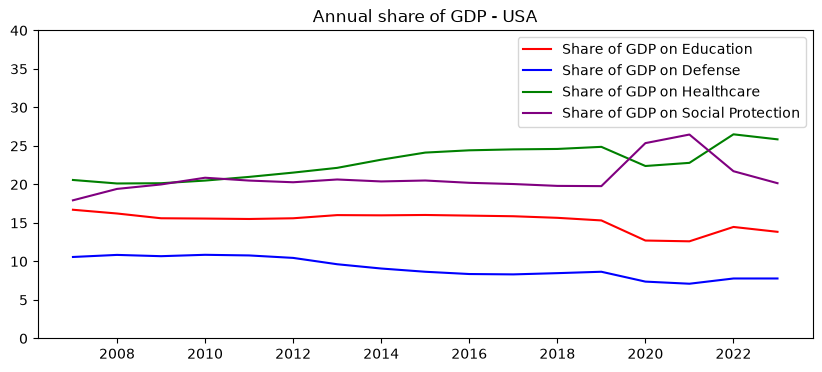

In [9]:
print(gov_spending_per_function["year"].unique())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(gov_spending_per_function[gov_spending_per_function["code"]=="USA"]["year"], 
        gov_spending_per_function[gov_spending_per_function["code"]=="USA"]["education"],
        color="red", label="Share of GDP on Education")
ax.plot(gov_spending_per_function[gov_spending_per_function["code"]=="USA"]["year"], 
        gov_spending_per_function[gov_spending_per_function["code"]=="USA"]["defense"],
        color="blue", label="Share of GDP on Defense")
ax.plot(gov_spending_per_function[gov_spending_per_function["code"]=="USA"]["year"], 
        gov_spending_per_function[gov_spending_per_function["code"]=="USA"]["healthcare"],
        color="green", label="Share of GDP on Healthcare")
ax.plot(gov_spending_per_function[gov_spending_per_function["code"]=="USA"]["year"], 
        gov_spending_per_function[gov_spending_per_function["code"]=="USA"]["social_protection"],
        color="purple", label="Share of GDP on Social Protection")
ax.set_title("Annual share of GDP - USA")
ax.set_ylim(bottom=0, top=40)
ax.legend(loc="upper right")
plt.show()


In [22]:
# Graph function

def simple_plot_graph(data, country1, country2, metric):

    df1 = data[data["entity"] == country1].sort_values("year")
    df2 = data[data["entity"] == country2].sort_values("year")

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df1["year"], df1[metric], color="red", label=country1)
    ax.plot(df2["year"], df2[metric], color="green", label=country2)

    ax.set_title(f"Annual comparison of {metric}")
    ax.set_xlabel("Year")
    ax.set_ylabel(metric)
    ax.legend(loc="upper left")
    ax.set_ylim(bottom=0)

    plt.tight_layout()
    plt.show()

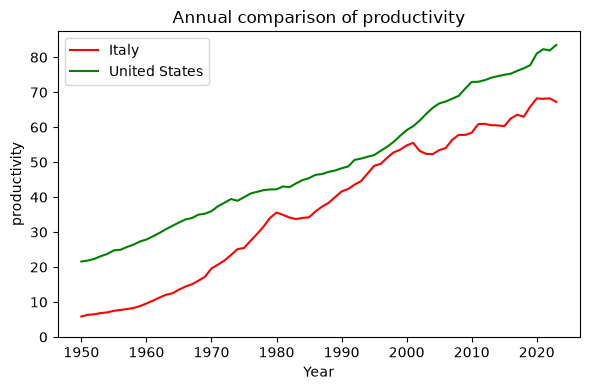

In [32]:
simple_plot_graph(productivity, "Italy", "United States", "productivity")

In [35]:
# Government revenues as share of GDP

gov_revenue = pd.read_csv("https://ourworldindata.org/grapher/government-revenues-as-a-share-of-gdp-imf.csv?v=1&csvType=full&useColumnShortNames=true", 
                          storage_options = {'User-Agent': 'Our World In Data data fetch/1.0'})

metadata_gov_rev = requests.get("https://ourworldindata.org/grapher/government-revenues-as-a-share-of-gdp-imf.metadata.json?v=1&csvType=full&useColumnShortNames=true").json()

In [37]:
gov_revenue['gdp_share'] = gov_revenue['_17_1_1__gr_g14_gdp']
gov_revenue = gov_revenue.drop(columns=['_17_1_1__gr_g14_gdp'])
gov_revenue

,entity,code,year,gdp_share
0,Afghanistan,AFG,2003,12.10
1,Afghanistan,AFG,2004,17.62
2,Afghanistan,AFG,2005,18.09
3,Afghanistan,AFG,2006,30.22
4,Afghanistan,AFG,2007,36.64
...,...,...,...,...
3357,Zimbabwe,ZWE,2012,20.39
3358,Zimbabwe,ZWE,2015,19.00
3359,Zimbabwe,ZWE,2016,16.98
3360,Zimbabwe,ZWE,2017,13.90


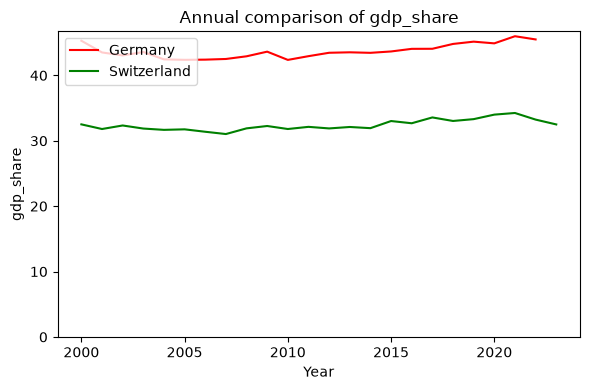

In [40]:
simple_plot_graph(gov_revenue, "Germany", "Switzerland", "gdp_share")

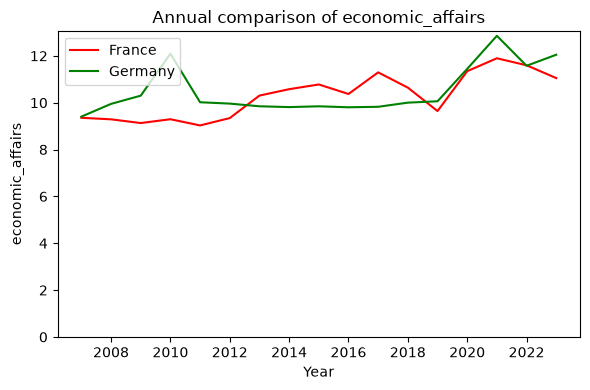

In [42]:
simple_plot_graph(gov_spending_per_function, "France", "Germany", "economic_affairs")

In [53]:
# Multicountry comparison chart

def multi_country_chart(data, countries, metric):
    clean_data = data[data['entity'].isin(countries)]
    colors = ['red', 'green', 'blue', 'purple', 'black', 'orange']

    fig, ax = plt.subplots(figsize=(8,6))
    for key,value in enumerate(countries):
        ax.plot(clean_data[clean_data['entity']==value]['year'], clean_data[clean_data['entity']==value][metric], color=colors[key], label=countries[key])

    ax.set_title(f"Country comparison on {metric}")
    ax.legend(loc='upper left')
    plt.show()

Index(['entity', 'code', 'year', 'social_protection', 'healthcare',
       'general_public', 'education', 'economic_affairs', 'defense',
       'public_safety', 'housing_community', 'culture_religion',
       'environment'],
      dtype='str')


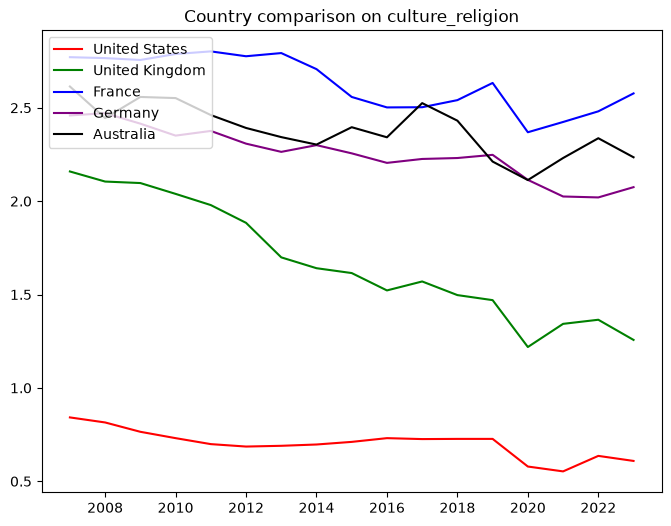

In [66]:
print(gov_spending_per_function.columns)
multi_country_chart(gov_spending_per_function, ["United States", "United Kingdom", "France", "Germany", "Australia"], "culture_religion")